本 notebook 是 [M03.6 实验设计（DOE）](../notes/06-design-of-experiments.qmd) 的实例讲解。

1. 1. 全因子设计与交互项
2. 2. 半分数设计与混杂
3. 3. 二次响应面与解析最优点
4. 4. LHS 边缘分层与覆盖检查

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.spatial.distance import pdist
from scipy.stats import qmc

from semiai.plotting import BLUE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 全因子设计与交互项

在三个二水平因子上构造完整设计，以无噪声已知函数检查系数恢复和正交性。

In [2]:
X = np.array(list(product([-1.0, 1.0], repeat=3)))
A, B, C = X.T
D = np.column_stack([np.ones(len(X)), A, B, C, A * B, A * C, B * C, A * B * C])
truth = np.array([5, 1.2, -0.8, 0.3, 2.0, 0, 0, 0])
y = D @ truth
coef = np.linalg.lstsq(D, y, rcond=None)[0]
print("系数:", coef, "\n设计内积:\n", D.T @ D)
print("A 的高低水平平均差:", y[A == 1].mean() - y[A == -1].mean())
assert np.allclose(coef, truth)
assert np.allclose(D.T @ D, 8 * np.eye(8))

系数: [ 5.00000000e+00  1.20000000e+00 -8.00000000e-01  3.00000000e-01
  2.00000000e+00  3.71833107e-16 -1.27767254e-16 -3.87661999e-17] 
设计内积:
 [[8. 0. 0. 0. 0. 0. 0. 0.]
 [0. 8. 0. 0. 0. 0. 0. 0.]
 [0. 0. 8. 0. 0. 0. 0. 0.]
 [0. 0. 0. 8. 0. 0. 0. 0.]
 [0. 0. 0. 0. 8. 0. 0. 0.]
 [0. 0. 0. 0. 0. 8. 0. 0.]
 [0. 0. 0. 0. 0. 0. 8. 0.]
 [0. 0. 0. 0. 0. 0. 0. 8.]]
A 的高低水平平均差: 2.4000000000000004


读法：±1 编码中的主效应系数是高低水平平均差的一半；交互项表示一个因子的作用依赖另一个因子。饱和设计没有剩余自由度估计噪声。

## 2. 半分数设计与混杂

选择 C=AB 的四个点，直接检查主效应与二阶交互列重合，显示预算减少的代价。

In [3]:
half = X[C == A * B]
a, b, c = half.T
Dh = np.column_stack([np.ones(len(a)), a, b, c, a * b, a * c, b * c])
print("半分数设计:\n", half)
print("列 a 与 bc 相同:", np.array_equal(a, b * c))
print("列 b 与 ac 相同:", np.array_equal(b, a * c))
print("列 c 与 ab 相同:", np.array_equal(c, a * b))
print("包含主效应和二阶交互时的秩:", np.linalg.matrix_rank(Dh), "列数:", Dh.shape[1])
assert np.array_equal(c, a * b)

半分数设计:
 [[-1. -1.  1.]
 [-1.  1. -1.]
 [ 1. -1. -1.]
 [ 1.  1.  1.]]
列 a 与 bc 相同: True
列 b 与 ac 相同: True
列 c 与 ab 相同: True
包含主效应和二阶交互时的秩: 4 列数: 7


读法：这是分辨率 III 设计，主效应与二因子交互混杂；即使输出没有噪声，也不能从这四点唯一分离它们。需要物理稀疏假设或补充 foldover 设计。

## 3. 二次响应面与解析最优点

用二维中心复合设计恢复一个正定二次函数，比较拟合驻点与解析驻点。

In [4]:
factorial = np.array(list(product([-1.0, 1.0], repeat=2)))
alpha = np.sqrt(2.0)
axial = np.array([[alpha, 0], [-alpha, 0], [0, alpha], [0, -alpha]])
points = np.vstack([factorial, axial, np.zeros((4, 2))])
a, b = points.T
D = np.column_stack([np.ones(len(a)), a, b, a * b, a * a, b * b])
truth = np.array([2.0, -1.0, 0.8, 0.4, 1.5, 1.0])
y = D @ truth
coef = np.linalg.lstsq(D, y, rcond=None)[0]
H = np.array([[2 * coef[4], coef[3]], [coef[3], 2 * coef[5]]])
optimum = np.linalg.solve(H, -coef[1:3])
exact = np.linalg.solve([[3, 0.4], [0.4, 2]], [1, -0.8])
print("拟合系数:", coef, "驻点:", optimum, "Hessian 特征值:", np.linalg.eigvalsh(H))
print("解析驻点误差:", np.linalg.norm(optimum - exact))
assert np.allclose(optimum, exact, atol=1e-12)

拟合系数: [ 2.  -1.   0.8  0.4  1.5  1. ] 驻点: [ 0.39726027 -0.47945205] Hessian 特征值: [1.85968758 3.14031242]
解析驻点误差: 8.899114524108741e-16


读法：无噪声、模型正确时可恢复解析结果；重复中心点用于有噪声实验的纯误差估计，本例重复并不会创造新的设计秩。最优点仍需可行性与确认运行。

## 4. LHS 边缘分层与覆盖检查

验证每个坐标的 n 个分层恰好各占一个点，同时比较差异度和最小距离，不从单次随机比较推断普遍优越性。

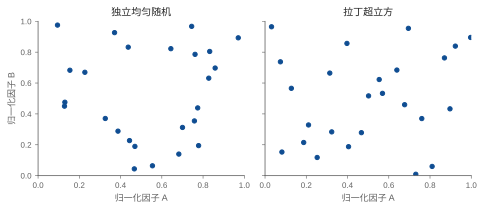

random 各维覆盖分层数 [15, 17] discrepancy 0.008726716159602924 min distance 0.02538345078250291
LHS 各维覆盖分层数 [25, 25] discrepancy 0.0015711987211106118 min distance 0.06949128790175035
对数映射后的前 3 个参数点:
 [[1.96481170e-01 3.69080471e+01]
 [4.16624878e-01 2.37276391e+01]
 [2.12449165e-02 2.02298393e+01]]


In [5]:
random_points = rng.uniform(size=(25, 2))
lhs = qmc.LatinHypercube(d=2, rng=np.random.default_rng(42)).random(25)
fig, axes = plt.subplots(1, 2, figsize=(6.8, 3), sharex=True, sharey=True)
for ax, points, title in zip(
    axes, [random_points, lhs], ["独立均匀随机", "拉丁超立方"], strict=True
):
    ax.scatter(points[:, 0], points[:, 1], s=19, color=BLUE)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="归一化因子 A", title=title)
axes[0].set_ylabel("归一化因子 B")
fig.tight_layout()
plt.show()

for name, points in [("random", random_points), ("LHS", lhs)]:
    occupancy = [len(np.unique(np.floor(points[:, j] * 25).astype(int))) for j in range(2)]
    print(
        name,
        "各维覆盖分层数",
        occupancy,
        "discrepancy",
        qmc.discrepancy(points),
        "min distance",
        pdist(points).min(),
    )
assert all(len(np.unique(np.floor(lhs[:, j] * 25))) == 25 for j in range(2))
# 正值因子的对数映射：归一化 u 均匀并不意味着物理量均匀。
physical = 10 ** qmc.scale(lhs, [-2.0, 1.0], [2.0, 3.0])
print("对数映射后的前 3 个参数点:\n", physical[:3])

读法：LHS 保证一维边缘分层，不保证所有二维格子被填满，也不自动满足物理可行约束。对数映射改变了物理空间中的采样密度。

## 小结

DOE 用有限预算换取可解释的信息结构。设计矩阵决定哪些效应可分，重复与随机化约束噪声解释，响应面提供局部曲率，LHS 提供边缘覆盖。先定义问题，再检查设计，最后用独立确认运行核验结论。